number of loaded training images:  555
loaded 70 training batches.
number of loaded val images:  186
loaded 24 validation batches.
data_batch.size= torch.Size([8, 1, 256, 256])

epoch  1  started!  LR= [0.0001]
train_loss:  0.4606161040919168
val_loss:  0.4888497901459535
Validation_Dice Score = 0.375216484070
The best model saved...
Best validation dice= 0.3752164840698242  in epoch  1
Epoch finished in 4.802239879965782 seconds.


epoch  2  started!  LR= [0.0001]
train_loss:  0.26407236882618496
val_loss:  0.28284340848525363
Validation_Dice Score = 0.600180923939
The best model saved...
Best validation dice= 0.6001809239387512  in epoch  2
Epoch finished in 2.6351660839281976 seconds.


epoch  3  started!  LR= [0.0001]
train_loss:  0.1988267781479018
val_loss:  0.20369248340527216
Validation_Dice Score = 0.645486116409
The best model saved...
Best validation dice= 0.6454861164093018  in epoch  3
Epoch finished in 2.503763338085264 seconds.


epoch  4  started!  LR= [0.0001]
train_lo

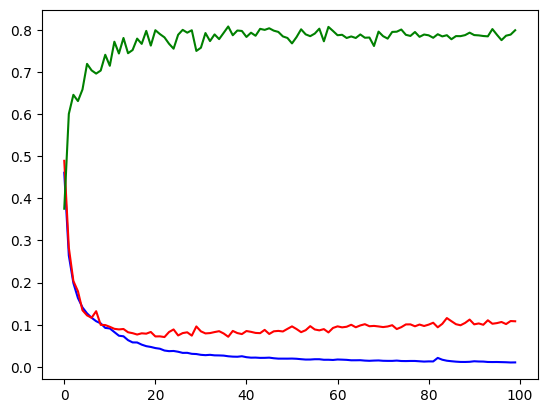

number of loaded test images:  186
loaded 24 test batches.
test Dice Score = 0.802003383636


In [3]:
# %%
ROOT = '/home/jupyter-r.yazdi/myproject/dti3d/0pycodes/UnetMaxsig/BUSI_WHU/'
config = {
    "lr": 1e-4,
    "batch_size": 8,
    "epochs": 100,
    "segformer_variant": "b0",       # b0 (smallest/fastest) ... b5 (largest)
    "maxsig_stages": (1, 2),         # which encoder stages get MaxSigGate; mirrors maxsig_down_stages in your UNet notebook
    "maxsig_kernel": 3,
    "gamma_init": 0.0,               # 0 => baseline SegFormer at init, MaxSig mixed in as it trains
    }

# %%
from time import perf_counter
import numpy as np
import cv2
import matplotlib.pyplot as plt

import os
from glob import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torchvision import transforms
import torchvision.transforms.functional as TF
from torchvision.utils import make_grid
from PIL import Image

from torch.optim.lr_scheduler import StepLR
from torch.utils.data import DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

from transformers import SegformerConfig, SegformerDecodeHead

# %%
#dataset
# Training from scratch, so no pretrained encoder to match -> we keep the
# image as single-channel grayscale, same as the UNet version. Mask handling
# is unchanged.
from torch.utils.data import Dataset
class mydataset(Dataset):
    def __init__(self,images_dir,masks_dir,transforms_img=None):
        self.images_dir=images_dir
        self.masks_dir=masks_dir
        self.transforms_img=transforms_img
        self.mask_names= glob(masks_dir + "*.bmp")

    def __len__(self):
        return len(self.mask_names)

    def __getitem__(self,index):
        mask_name=self.mask_names[index]
        mask=cv2.imread(mask_name,cv2.IMREAD_ANYDEPTH)
        mask = (mask - mask.min()) / (mask.max() - mask.min())#ejbari
        mask= (mask>0).astype(np.float32)
        mask = cv2.resize(mask, (256, 256), interpolation=cv2.INTER_AREA)

        imgn=mask_name.replace('/masks/','/images/').replace('_anno.bmp','.bmp')

        image=cv2.imread(imgn,cv2.IMREAD_ANYDEPTH)
        image = (image - image.min()) / (image.max() - image.min()).astype(np.float32)#ejbari
        image = cv2.resize(image, (256, 256), interpolation=cv2.INTER_AREA)

        if self.transforms_img is not None:
            transformed = self.transforms_img(image=image, mask=mask)
            image = transformed["image"]
            mask = transformed["mask"]

        return image, mask

# %%
#train dataset

images_dir= ROOT + 'dataset/train/images/'
masks_dir= ROOT + 'dataset/train/masks/'
batch_size=config['batch_size']
shuffle=True

train_transform = A.Compose([

    #A.RandomCrop(256,256,always_apply=True, p=1.0),
    #A.UnsharpMask (blur_limit=(3, 5), sigma_limit=0, alpha=(0.2, 0.5), threshold=10, always_apply=False, p=0.1),
    #A.RandomGamma (gamma_limit=(80, 150), always_apply=False, p=0.1),
    #A.RandomBrightnessContrast (brightness_limit=0.2, contrast_limit=0.5, brightness_by_max=True, always_apply=False, p=0.25),
    #A.PadIfNeeded (min_height=1048, min_width=790, border_mode=cv2.BORDER_CONSTANT, value=0,always_apply=True, p=1.0),

    #A.Resize(256,256),
    ToTensorV2()])


train_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=train_transform)
print("number of loaded training images: ",train_ds.__len__())

train_dataset = DataLoader(train_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(train_dataset), "training batches.")

# %%
#val dataset

images_dir= ROOT + 'dataset/val/images/'
masks_dir= ROOT + 'dataset/val/masks/'
batch_size=config['batch_size']
shuffle=True

val_transform = A.Compose([

    #A.PadIfNeeded (min_height=790, min_width=790, border_mode=cv2.BORDER_CONSTANT, value=0,always_apply=True,  p=1.0),
    #A.Resize(256,256),
    ToTensorV2()])

val_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=val_transform)
print("number of loaded val images: ",val_ds.__len__())

val_dataset = DataLoader(val_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(val_dataset), "validation batches.")

# %%
# ============================================================
# MaxSigLayerNormalized — copied unchanged from your notebook.
# ============================================================
class MaxSigLayerNormalized(nn.Module):
    """
    Args:
        ch_in (int): input channels
        ch_out (int): output channels
        kernel_size (int): odd recommended
        stride (int): keep 1 to preserve H,W
        use_sigmoid_input (bool): apply sigmoid(x) before unfolding
    """
    def __init__(
        self,
        ch_in: int,
        ch_out: int,
        kernel_size: int,
        stride: int = 1,
        use_sigmoid_input: bool = True,
    ):
        super().__init__()
        assert kernel_size >= 1
        self.ch_in = ch_in
        self.ch_out = ch_out
        self.kernel_size = kernel_size
        self.stride = stride
        self.use_sigmoid_input = use_sigmoid_input

        self.padding = (kernel_size - 1) // 2
        self.kernel_area = kernel_size ** 2
        self.center_index = self.kernel_area // 2

        # learnable patch weights / bias (shared)
        self.weight = nn.Parameter(torch.rand(1, 1, self.kernel_area, 1, 1))
        self.bias   = nn.Parameter(torch.zeros(1, 1, self.kernel_area, 1, 1))

        # learnable scalars
        self.weight_center = nn.Parameter(torch.tensor(1.0))
        self.weight_median = nn.Parameter(torch.tensor(1.0))

        # proper projection
        self.proj = nn.Conv2d(ch_in, ch_out, kernel_size=1, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, C_in, H, W = x.shape
        assert C_in == self.ch_in, f"Expected {self.ch_in} channels, got {C_in}"

        x_in = torch.sigmoid(x) if self.use_sigmoid_input else x

        x_unfold = F.unfold(
            x_in,
            kernel_size=self.kernel_size,
            padding=self.padding,
            stride=self.stride,
        )  # (B, C_in*K*K, L)

        _, CK2, L = x_unfold.shape
        assert CK2 == C_in * self.kernel_area

        out_h = (H + 2 * self.padding - self.kernel_size) // self.stride + 1
        out_w = (W + 2 * self.padding - self.kernel_size) // self.stride + 1

        x_unfold = x_unfold.view(B, C_in, self.kernel_area, out_h, out_w)

        w = torch.sigmoid(self.weight)  # (1,1,K*K,1,1)
        b = torch.sigmoid(self.bias)    # (1,1,K*K,1,1)

        D = torch.maximum(w, x_unfold) + b  # (B,C,K*K,out_h,out_w)

        mean_stat = torch.mean(D, dim=2)         # (B,C,out_h,out_w)
        median_stat, _ = torch.median(D, dim=2)  # (B,C,out_h,out_w)

        center_values = x_unfold[:, :, self.center_index, :, :]  # (B,C,out_h,out_w)

        out = (
            self.weight_center * center_values
            + self.weight_median * median_stat
            - mean_stat
        )  # (B,C_in,out_h,out_w)

        out = self.proj(out)  # (B,C_out,out_h,out_w)
        return out


# ============================================================
# MaxSigGate — the Segformer analogue of your UNet's
# DownBlockWithMaxSig. In the UNet notebook, MaxSig was injected
# after a DoubleConv block, before pooling, as a gated residual:
#     x = conv(x); x = x + gamma * post(maxsig(x))
# A Segformer encoder stage (SegformerStage: overlap-patch-embed ->
# transformer blocks -> layernorm -> reshape to (B,C,H,W)) plays the
# same structural role as a UNet down-block: it's the thing that
# produces a spatial feature map at one resolution before the next
# stage/pool. So we apply the exact same gated-residual pattern
# right after a stage's (B,C,H,W) output.
# gamma starts at 0 => the model is architecturally identical to a
# baseline (MaxSig-free) SegFormer at initialization, and the network
# learns how much MaxSig signal to mix in during training.
# ============================================================
class MaxSigGate(nn.Module):
    def __init__(self, channels: int, kernel_size: int = 3, gamma_init: float = 0.0,
                 use_sigmoid_input: bool = True):
        super().__init__()
        self.maxsig = MaxSigLayerNormalized(
            ch_in=channels, ch_out=channels, kernel_size=kernel_size,
            stride=1, use_sigmoid_input=use_sigmoid_input,
        )
        # light post-processing helps stabilize, same as the UNet version
        self.post = nn.Sequential(
            nn.BatchNorm2d(channels),
            nn.LeakyReLU(0.1, inplace=True),
        )
        self.gamma = nn.Parameter(torch.tensor(gamma_init))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        m = self.maxsig(x)
        m = self.post(m)
        return x + self.gamma * m


# ============================================================
# Standalone Mix Transformer (MiT) encoder — SegFormer's encoder,
# reimplemented here from the paper instead of pulled out of
# transformers.SegformerModel.
#
# Why: SegformerModel's *internal* module layout (stages vs.
# encoder.patch_embeddings/block/layer_norm, etc.) has changed
# across transformers versions, so code that reaches into
# `model.stages` breaks on version mismatches (that's the
# AttributeError above). SegformerConfig (hyperparameters) and
# SegformerDecodeHead (decoder, takes a tuple of per-stage
# (B,C,H,W) feature maps) are the stable, public parts of the API,
# so we only depend on those and rebuild the encoder ourselves.
# Since training is from scratch anyway, there's no pretrained
# encoder weight layout we need to match.
# ============================================================
class OverlapPatchEmbed(nn.Module):
    """Conv-based patch embedding with overlapping patches (stride < kernel_size)."""
    def __init__(self, in_ch, embed_dim, patch_size, stride):
        super().__init__()
        self.proj = nn.Conv2d(in_ch, embed_dim, kernel_size=patch_size,
                               stride=stride, padding=patch_size // 2)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = self.proj(x)
        _, _, H, W = x.shape
        x = x.flatten(2).transpose(1, 2)   # (B, N, C)
        x = self.norm(x)
        return x, H, W


class EfficientSelfAttention(nn.Module):
    """Multi-head self-attention with spatial-reduction on K/V (SegFormer's SRA)."""
    def __init__(self, dim, num_heads, sr_ratio, attn_drop=0.0, proj_drop=0.0):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.q = nn.Linear(dim, dim, bias=True)
        self.kv = nn.Linear(dim, dim * 2, bias=True)
        self.proj = nn.Linear(dim, dim)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj_drop = nn.Dropout(proj_drop)
        self.sr_ratio = sr_ratio
        if sr_ratio > 1:
            self.sr = nn.Conv2d(dim, dim, kernel_size=sr_ratio, stride=sr_ratio)
            self.norm = nn.LayerNorm(dim)

    def forward(self, x, H, W):
        B, N, C = x.shape
        q = self.q(x).reshape(B, N, self.num_heads, self.head_dim).permute(0, 2, 1, 3)

        if self.sr_ratio > 1:
            x_ = x.permute(0, 2, 1).reshape(B, C, H, W)
            x_ = self.sr(x_).reshape(B, C, -1).permute(0, 2, 1)
            x_ = self.norm(x_)
            kv = self.kv(x_)
        else:
            kv = self.kv(x)
        kv = kv.reshape(B, -1, 2, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        k, v = kv[0], kv[1]

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        attn = self.attn_drop(attn)

        out = (attn @ v).transpose(1, 2).reshape(B, N, C)
        out = self.proj(out)
        out = self.proj_drop(out)
        return out


class DWConv(nn.Module):
    """Depthwise 3x3 conv used inside Mix-FFN to inject local/positional info."""
    def __init__(self, dim):
        super().__init__()
        self.dwconv = nn.Conv2d(dim, dim, kernel_size=3, padding=1, groups=dim)

    def forward(self, x, H, W):
        B, N, C = x.shape
        x = x.transpose(1, 2).reshape(B, C, H, W)
        x = self.dwconv(x)
        x = x.flatten(2).transpose(1, 2)
        return x


class MixFFN(nn.Module):
    """SegFormer's Mix-FFN: Linear -> DWConv -> GELU -> Linear."""
    def __init__(self, dim, hidden_dim, drop=0.0):
        super().__init__()
        self.fc1 = nn.Linear(dim, hidden_dim)
        self.dwconv = DWConv(hidden_dim)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden_dim, dim)
        self.drop = nn.Dropout(drop)

    def forward(self, x, H, W):
        x = self.fc1(x)
        x = self.dwconv(x, H, W)
        x = self.act(x)
        x = self.drop(x)
        x = self.fc2(x)
        x = self.drop(x)
        return x


class DropPath(nn.Module):
    """Stochastic depth, applied per-sample."""
    def __init__(self, drop_prob=0.0):
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x):
        if self.drop_prob == 0.0 or not self.training:
            return x
        keep_prob = 1 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = keep_prob + torch.rand(shape, dtype=x.dtype, device=x.device)
        random_tensor.floor_()
        return x.div(keep_prob) * random_tensor


class MixTransformerBlock(nn.Module):
    def __init__(self, dim, num_heads, mlp_ratio, sr_ratio, drop=0.0, attn_drop=0.0,
                 drop_path=0.0, layer_norm_eps=1e-6):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=layer_norm_eps)
        self.attn = EfficientSelfAttention(dim, num_heads, sr_ratio, attn_drop, drop)
        self.drop_path = DropPath(drop_path)
        self.norm2 = nn.LayerNorm(dim, eps=layer_norm_eps)
        self.mlp = MixFFN(dim, dim * mlp_ratio, drop)

    def forward(self, x, H, W):
        x = x + self.drop_path(self.attn(self.norm1(x), H, W))
        x = x + self.drop_path(self.mlp(self.norm2(x), H, W))
        return x


class MixVisionTransformerStage(nn.Module):
    """One encoder stage: overlap patch embed -> transformer blocks -> layernorm
    -> reshape back to (B, C, H, W). Plays the same structural role as a UNet
    down-block: it's what produces a spatial feature map at one resolution."""
    def __init__(self, in_ch, embed_dim, patch_size, stride, depth, num_heads, mlp_ratio,
                 sr_ratio, drop=0.0, attn_drop=0.0, drop_path_rates=None, layer_norm_eps=1e-6):
        super().__init__()
        self.patch_embed = OverlapPatchEmbed(in_ch, embed_dim, patch_size, stride)
        drop_path_rates = drop_path_rates or [0.0] * depth
        self.blocks = nn.ModuleList([
            MixTransformerBlock(embed_dim, num_heads, mlp_ratio, sr_ratio, drop, attn_drop,
                                 drop_path_rates[j], layer_norm_eps)
            for j in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim, eps=layer_norm_eps)

    def forward(self, x):
        x, H, W = self.patch_embed(x)
        for blk in self.blocks:
            x = blk(x, H, W)
        x = self.norm(x)
        B, N, C = x.shape
        x = x.transpose(1, 2).reshape(B, C, H, W)
        return x


class MixVisionTransformerEncoder(nn.Module):
    """Full 4-stage Mix Transformer encoder, built entirely from a SegformerConfig."""
    def __init__(self, config: SegformerConfig):
        super().__init__()
        depths = config.depths
        total_depth = sum(depths)
        dpr = [config.drop_path_rate * i / max(total_depth - 1, 1) for i in range(total_depth)]

        self.stages = nn.ModuleList()
        cur = 0
        in_ch = config.num_channels
        for i in range(config.num_encoder_blocks):
            stage_dpr = dpr[cur:cur + depths[i]]
            self.stages.append(MixVisionTransformerStage(
                in_ch=in_ch,
                embed_dim=config.hidden_sizes[i],
                patch_size=config.patch_sizes[i],
                stride=config.strides[i],
                depth=depths[i],
                num_heads=config.num_attention_heads[i],
                mlp_ratio=config.mlp_ratios[i],
                sr_ratio=config.sr_ratios[i],
                drop=config.hidden_dropout_prob,
                attn_drop=config.attention_probs_dropout_prob,
                drop_path_rates=stage_dpr,
                layer_norm_eps=config.layer_norm_eps,
            ))
            cur += depths[i]
            in_ch = config.hidden_sizes[i]

    def forward(self, x):
        hidden_states = []
        for stage in self.stages:
            x = stage(x)
            hidden_states.append(x)
        return hidden_states


# ============================================================
# SegFormer encoder + decode head, trained from scratch, with
# MaxSigGate applied after selected encoder stages.
# ============================================================
class SegFormerMaxSig(nn.Module):
    def __init__(
        self,
        out_size=(256, 256),
        variant="b0",
        maxsig_stages=(1, 2),     # which of the 4 encoder stages get MaxSig; mirrors maxsig_down_stages in the UNet notebook
        maxsig_kernel=3,
        gamma_init=0.0,
        use_sigmoid_input=True,
    ):
        super().__init__()

        # architecture presets from the SegFormer paper (encoder only differs
        # in depths / hidden_sizes; decoder head size also scales for b4/b5)
        variants = {
            "b0": dict(depths=[2, 2, 2, 2],  hidden_sizes=[32, 64, 160, 256],  decoder_hidden_size=256),
            "b1": dict(depths=[2, 2, 2, 2],  hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=256),
            "b2": dict(depths=[3, 4, 6, 3],  hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
            "b3": dict(depths=[3, 4, 18, 3], hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
            "b4": dict(depths=[3, 8, 27, 3], hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
            "b5": dict(depths=[3, 6, 40, 3], hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
        }
        preset = variants[variant]

        seg_config = SegformerConfig(
            num_channels=1,
            num_labels=1,
            depths=preset["depths"],
            hidden_sizes=preset["hidden_sizes"],
            decoder_hidden_size=preset["decoder_hidden_size"],
        )

        self.encoder = MixVisionTransformerEncoder(seg_config)   # encoder only (random init)
        self.decode_head = SegformerDecodeHead(seg_config)
        self.out_size = out_size

        maxsig_stages = set(maxsig_stages)
        self.maxsig_gates = nn.ModuleDict()
        for i in range(seg_config.num_encoder_blocks):
            if i in maxsig_stages:
                self.maxsig_gates[str(i)] = MaxSigGate(
                    channels=seg_config.hidden_sizes[i],
                    kernel_size=maxsig_kernel,
                    gamma_init=gamma_init,
                    use_sigmoid_input=use_sigmoid_input,
                )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        hidden_states = x
        encoder_hidden_states = []
        for i, stage in enumerate(self.encoder.stages):
            hidden_states = stage(hidden_states)                  # (B, C_i, H_i, W_i)
            if str(i) in self.maxsig_gates:
                hidden_states = self.maxsig_gates[str(i)](hidden_states)
            encoder_hidden_states.append(hidden_states)

        logits = self.decode_head(tuple(encoder_hidden_states))   # [B, 1, H/4, W/4]
        logits = F.interpolate(logits, size=self.out_size, mode="bilinear", align_corners=False)
        return logits


# %%
torch.manual_seed(42)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

data_batch,mask_name = next(iter(train_dataset))
print("data_batch.size=",data_batch.size())

model=SegFormerMaxSig(
    variant=config['segformer_variant'],
    maxsig_stages=config['maxsig_stages'],
    maxsig_kernel=config['maxsig_kernel'],
    gamma_init=config['gamma_init'],
).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model.parameters(),lr=config['lr'])

scheduler = StepLR(optimizer, step_size=100, gamma=0.83)
scaler = torch.amp.GradScaler('cuda')

best_valid_dice=0
best_epoch=0
train_loss_plot=[]
val_loss_plot=[]
val_dice_plot=[]
last_lr=scheduler.get_last_lr()

for epoch in range(config['epochs']):

    if(last_lr != scheduler.get_last_lr()):
        print(80*'-')
        print(f'The lr changed from {last_lr} to {scheduler.get_last_lr()}. thus previous best model loaded!')
        last_lr = scheduler.get_last_lr()

    print("\r\nepoch ",epoch+1," started!",' LR=', last_lr)

    t_start = perf_counter()

    #model training step
    running_loss = 0.0
    model.train()
    for inputs,mask in train_dataset:

        optimizer.zero_grad()
        with torch.autocast(device_type="cuda"):
            outputs = model(inputs.to(device))
            labels=mask.to(device).unsqueeze(1)
            loss = criterion(outputs, labels)

        running_loss += loss.item()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

    ep_loss=running_loss / len(train_dataset)
    print("train_loss: " ,ep_loss)
    train_loss_plot.append(ep_loss)
    scheduler.step()

    #model evaluation step
    dice_score = 0
    val_loss = 0.0
    with torch.no_grad():
        model.eval()
        for inputs,mask in val_dataset:

            inputs=inputs.to(device)
            preds =model(inputs)
            labels=mask.to(device).unsqueeze(1)
            loss = criterion(preds, labels)
            val_loss += loss.item()

            pred_sig=torch.sigmoid(preds)

            preds=(pred_sig>0.5).float()
            intersection=(preds * labels).sum()
            union=(preds + labels).sum()
            dice_score += (2 * intersection / union)

    ep_loss=val_loss / len(val_dataset)
    print("val_loss: " ,ep_loss)
    val_loss_plot.append(ep_loss)
    epoch_dc= float(dice_score/len(val_dataset))
    val_dice_plot.append(epoch_dc)
    print(f"Validation_Dice Score = {epoch_dc:.12f}")
    if(best_valid_dice< epoch_dc):
        best_valid_dice=epoch_dc
        best_epoch=epoch
        torch.save(model.state_dict(), 'best-model-segformer-maxsig.pt')
        print('The best model saved...')

    print('Best validation dice=',best_valid_dice, ' in epoch ', best_epoch+1)
    print(f"Epoch finished in {perf_counter()-t_start} seconds.\r\n")


# %%
plt.plot(train_loss_plot, color='blue',label='train_loss')
plt.plot(val_loss_plot, color='red',label='val_loss')
plt.plot(val_dice_plot ,color='green',label='val_dice')
plt.show()

# %%
#test dataset

images_dir= ROOT + 'dataset/test/images/'
masks_dir= ROOT + 'dataset/test/masks/'
batch_size=config['batch_size']
shuffle=True

test_transform = A.Compose([
    ToTensorV2()])

test_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=test_transform)
print("number of loaded test images: ",test_ds.__len__())

test_dataset = DataLoader(test_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(test_dataset), "test batches.")

# %%
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---- Binary semantic segmentation example ----
model=SegFormerMaxSig(
    variant=config['segformer_variant'],
    maxsig_stages=config['maxsig_stages'],
    maxsig_kernel=config['maxsig_kernel'],
    gamma_init=config['gamma_init'],
).to(device)
#model evaluation step
dice_score = 0
model.load_state_dict(torch.load('best-model-segformer-maxsig.pt'))
with torch.no_grad():
    model.eval()
    for inputs,mask in test_dataset:

        inputs=inputs.to(device)
        preds =model(inputs)
        labels=mask.to(device).unsqueeze(1)
        pred_sig=torch.sigmoid(preds)
        preds=(pred_sig>0.5).float()
        intersection=(preds * labels).sum()
        union=(preds + labels).sum()
        dice_score += (2 * intersection / union)

epoch_dc= float(dice_score/len(test_dataset))

print(f"test Dice Score = {epoch_dc:.12f}")

# %%